In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

In [20]:
# Set up matplotlib and seaborn for better visuals
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [21]:
# --- GLOBAL CONFIGURATION ---
DATASET_PATH = 'census2011.csv'
# Splitting percentages
TRAIN_SIZE = 0.70
VAL_SIZE = 0.15
TEST_SIZE = 0.15
RANDOM_SEED = 42

# Ensure the split sizes sum to 1 (or close to 1 due to floating point arithmetic)
assert abs(TRAIN_SIZE + VAL_SIZE + TEST_SIZE - 1.0) < 1e-6, "Split sizes must sum to 1.0"


In [24]:
# ==============================================================================
# 0. DATA PREPROCESSING AND SPLITTING
# ==============================================================================

print("--- 0. Data Preprocessing ---")

# Load the dataset
df = pd.read_csv(DATASET_PATH)

# Data Cleaning and Conversion
# 1. Clean 'Population': remove commas and convert to float
df['Population'] = df['Population'].astype(str).str.replace(',', '').astype(float)

# 2. Clean 'Growth': remove '%' and convert to float
df['Growth'] = df['Growth'].astype(str).str.replace(' %', '').astype(float)

# 3. Convert 'Sex-Ratio' and 'Literacy' to float
df['Sex-Ratio'] = df['Sex-Ratio'].astype(float)
df['Literacy'] = df['Literacy'].astype(float)

# Select relevant features for both tasks
FEATURES = ['Population', 'Growth', 'Sex-Ratio']


# Drop rows with any NaN values that might have been introduced during cleaning,
# although for this dataset, it's unlikely.
df_clean = df.dropna(subset=FEATURES + ['Literacy']).reset_index(drop=True)
print(f"Cleaned dataset size: {len(df_clean)} rows.")

--- 0. Data Preprocessing ---
Cleaned dataset size: 610 rows.


In [25]:
# --- Custom Train/Validation/Test Split Function ---
def train_val_test_split(df, train_ratio, val_ratio, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)

    # Calculate number of samples for each set
    n_samples = len(df)
    n_train = int(n_samples * train_ratio)
    n_val = int(n_samples * val_ratio)

    # Get shuffled indices
    indices = np.random.permutation(n_samples)

    # Split indices
    train_indices = indices[:n_train]
    val_indices = indices[n_train:n_train + n_val]
    test_indices = indices[n_train + n_val:]

    # Split the DataFrame
    train_df = df.iloc[train_indices].reset_index(drop=True)
    val_df = df.iloc[val_indices].reset_index(drop=True)
    test_df = df.iloc[test_indices].reset_index(drop=True)

    return train_df, val_df, test_df

# Perform the split
train_df, val_df, test_df = train_val_test_split(
    df_clean, TRAIN_SIZE, VAL_SIZE, RANDOM_SEED
)

print(f"Split sizes: Train={len(train_df)}, Val={len(val_df)}, Test={len(test_df)}")

Split sizes: Train=427, Val=91, Test=92


In [26]:
# --- Custom Scaler Class (Standard Scaler) ---
class StandardScaler:
    def __init__(self):
        self.mean = None
        self.std = None

    def fit(self, X):
        self.mean = np.mean(X, axis=0)
        self.std = np.std(X, axis=0)
        # Handle zero standard deviation to prevent division by zero
        self.std[self.std == 0] = 1.0
        return self

    def transform(self, X):
        if self.mean is None or self.std is None:
            raise Exception("Scaler not fitted. Call fit() first.")
        return (X - self.mean) / self.std

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)

In [27]:
# --- Custom Metrics Functions ---
def mean_squared_error(y_true, y_pred):
    """Mean Squared Error (MSE)"""
    return np.mean((y_true - y_pred) ** 2)

def root_mean_squared_error(y_true, y_pred):
    """Root Mean Squared Error (RMSE)"""
    return np.sqrt(mean_squared_error(y_true, y_pred))

def mean_absolute_error(y_true, y_pred):
    """Mean Absolute Error (MAE)"""
    return np.mean(np.abs(y_true - y_pred))

def r2_score(y_true, y_pred):
    """R-squared (R^2) Score"""
    ss_total = np.sum((y_true - np.mean(y_true)) ** 2)
    ss_residual = np.sum((y_true - y_pred) ** 2)
    return 1 - (ss_residual / ss_total)

In [28]:
# ==============================================================================
# TASK 1: LINEAR REGRESSION with Gradient Descent Variants (BGD and SGD)
# Target Variable: 'Literacy'
# ==============================================================================

print("\n" + "="*80)
print("TASK 1: LINEAR REGRESSION (Batch GD and SGD) - Target: Literacy Rate")
print("="*80)



TASK 1: LINEAR REGRESSION (Batch GD and SGD) - Target: Literacy Rate


In [29]:
# 1. Prepare Data for Task 1
X_train_raw = train_df[FEATURES].values
y_train = train_df['Literacy'].values
X_val_raw = val_df[FEATURES].values
y_val = val_df['Literacy'].values
X_test_raw = test_df[FEATURES].values
y_test = test_df['Literacy'].values

# Scale features
scaler_lr = StandardScaler().fit(X_train_raw)
X_train_scaled = scaler_lr.transform(X_train_raw)
X_val_scaled = scaler_lr.transform(X_val_raw)
X_test_scaled = scaler_lr.transform(X_test_raw)

# Add intercept term (column of ones) to X
def add_intercept(X):
    return np.concatenate((np.ones((X.shape[0], 1)), X), axis=1)

X_train = add_intercept(X_train_scaled)
X_val = add_intercept(X_val_scaled)
X_test = add_intercept(X_test_scaled)

# Reshape y to (m, 1) for consistent matrix operations
y_train = y_train.reshape(-1, 1)
y_val = y_val.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)

In [30]:
# --- Custom Linear Regression Class with GD and SGD ---
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=1000, gradient_type='batch'):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.gradient_type = gradient_type
        self.theta = None
        self.loss_history = []

    def _hypothesis(self, X):
        """Calculates h_theta(X) = X * theta"""
        return X @ self.theta

    def _calculate_loss(self, X, y):
        """Calculates Mean Squared Error (MSE) / 2m"""
        m = len(y)
        predictions = self._hypothesis(X)
        return (1/(2 * m)) * np.sum((predictions - y) ** 2)

    def fit(self, X, y):
        m, n = X.shape
        # Initialize parameters (weights) with zeros
        self.theta = np.zeros((n, 1))
        self.loss_history = []

        if self.gradient_type == 'batch':
            for _ in range(self.n_iterations):
                # Calculate the gradient using ALL training examples
                predictions = self._hypothesis(X)
                errors = predictions - y
                gradient = (1/m) * X.T @ errors

                # Update weights
                self.theta = self.theta - self.learning_rate * gradient

                # Record loss for plotting
                self.loss_history.append(self._calculate_loss(X, y))

        elif self.gradient_type == 'stochastic':
            # SGD typically runs for 'epochs' over the whole dataset
            for epoch in range(self.n_iterations): # Here n_iterations means n_epochs
                # Shuffle data for each epoch
                indices = np.random.permutation(m)
                X_shuffled = X[indices]
                y_shuffled = y[indices]

                # Iterate through individual samples
                for i in range(m):
                    x_i = X_shuffled[i, :].reshape(1, -1)
                    y_i = y_shuffled[i, :].reshape(1, -1)

                    # Calculate the gradient for a single instance
                    prediction = self._hypothesis(x_i)
                    error = prediction - y_i
                    gradient = x_i.T * error # Gradient is X_i * error

                    # Update weights
                    self.theta = self.theta - self.learning_rate * gradient

                # Record loss after each epoch
                self.loss_history.append(self._calculate_loss(X, y))

        return self

    def predict(self, X):
        """Predicts the target variable for input X"""
        return self._hypothesis(X)

In [31]:
# 2. Training and Hyperparameter Tuning

# Define learning rates to test
learning_rates = [0.001, 0.01, 0.1, 0.3]
n_iterations = 500  # Number of iterations/epochs

# Store results for plotting
bgd_results = {}
sgd_results = {}

# Train Batch Gradient Descent models
print("\nTraining Batch Gradient Descent (BGD) models...")
for alpha in learning_rates:
    print(f"  -> Training BGD with alpha={alpha}")
    model = LinearRegressionGD(learning_rate=alpha, n_iterations=n_iterations, gradient_type='batch')
    model.fit(X_train, y_train)
    bgd_results[alpha] = model

# Train Stochastic Gradient Descent models
print("\nTraining Stochastic Gradient Descent (SGD) models...")
for alpha in learning_rates:
    print(f"  -> Training SGD with alpha={alpha}")
    # SGD typically uses smaller iterations (epochs) or a decaying learning rate
    model = LinearRegressionGD(learning_rate=alpha, n_iterations=n_iterations, gradient_type='stochastic')
    model.fit(X_train, y_train)
    sgd_results[alpha] = model


Training Batch Gradient Descent (BGD) models...
  -> Training BGD with alpha=0.001
  -> Training BGD with alpha=0.01
  -> Training BGD with alpha=0.1
  -> Training BGD with alpha=0.3

Training Stochastic Gradient Descent (SGD) models...
  -> Training SGD with alpha=0.001
  -> Training SGD with alpha=0.01
  -> Training SGD with alpha=0.1
  -> Training SGD with alpha=0.3


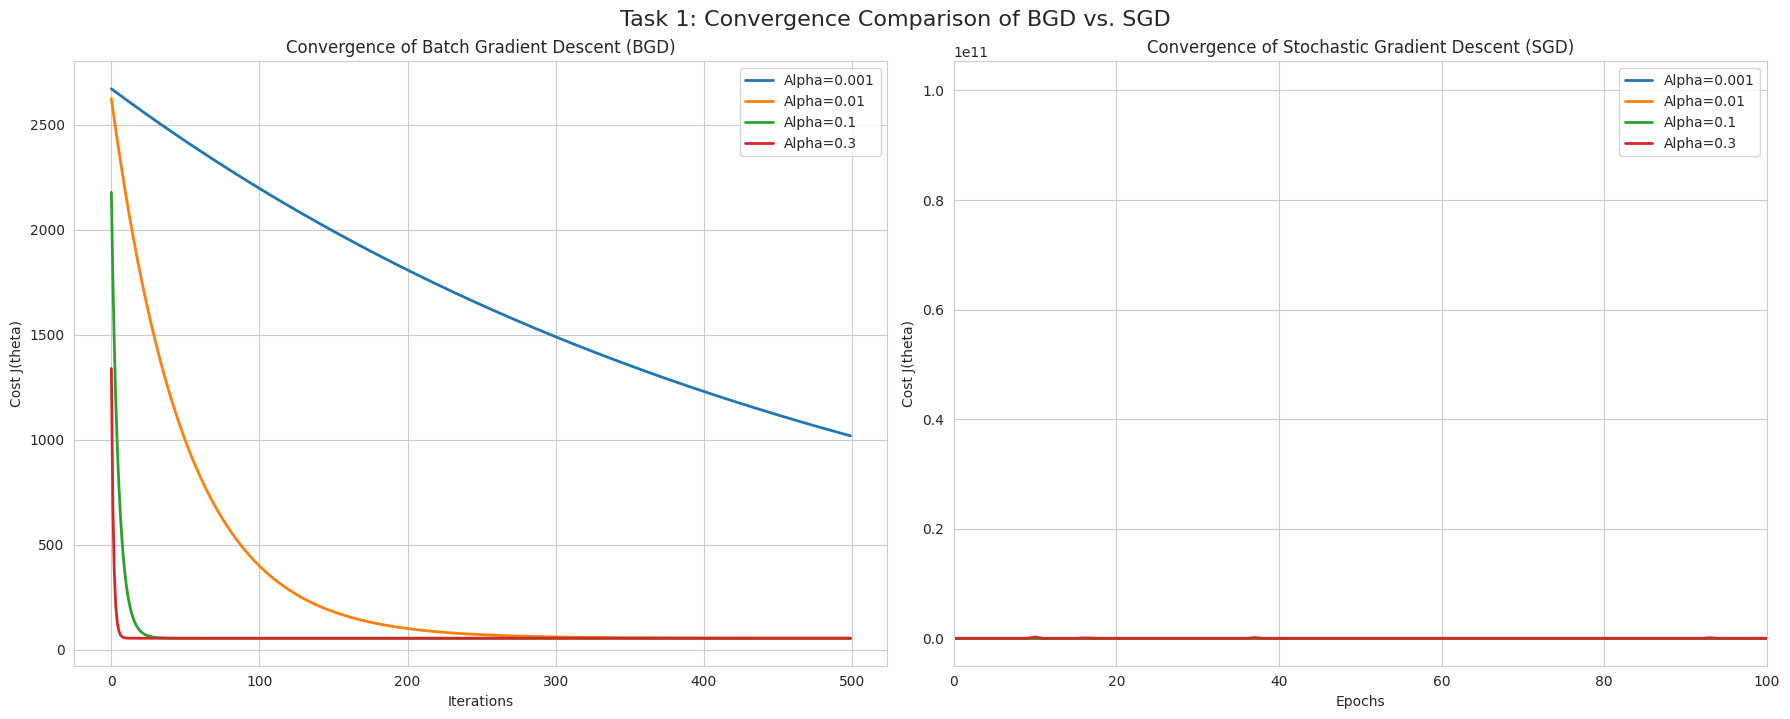

In [32]:
# --- 3. Convergence Comparison Plot ---
plt.figure(figsize=(18, 7))

# Plot BGD Convergence
plt.subplot(1, 2, 1)
for alpha, model in bgd_results.items():
    plt.plot(model.loss_history, label=f'Alpha={alpha}', linewidth=2)
plt.title('Convergence of Batch Gradient Descent (BGD)')
plt.xlabel('Iterations')
plt.ylabel('Cost J(theta)')
plt.legend()
plt.grid(True)
plt.tight_layout()

# Plot SGD Convergence
plt.subplot(1, 2, 2)
for alpha, model in sgd_results.items():
    plt.plot(model.loss_history, label=f'Alpha={alpha}', linewidth=2)
plt.title('Convergence of Stochastic Gradient Descent (SGD)')
plt.xlabel('Epochs')
plt.ylabel('Cost J(theta)')
plt.legend()
plt.grid(True)
plt.xlim(0, 100) # Limit x-axis to the first 100 epochs for better visualization of initial convergence
plt.tight_layout()
plt.suptitle('Task 1: Convergence Comparison of BGD vs. SGD', fontsize=16, y=1.02)
plt.show()

In [33]:
# 4. Model Selection and Final Evaluation (Choosing the best model)
# We choose the model with the lowest validation MSE for final evaluation.

def evaluate_model_set(results, X_val, y_val):
    best_alpha = None
    best_mse = float('inf')
    best_model = None
    evaluation_metrics = {}

    for alpha, model in results.items():
        y_val_pred = model.predict(X_val)
        mse = mean_squared_error(y_val, y_val_pred)

        if mse < best_mse:
            best_mse = mse
            best_alpha = alpha
            best_model = model

        evaluation_metrics[alpha] = {
            'MSE': mse,
            'RMSE': root_mean_squared_error(y_val, y_val_pred),
            'MAE': mean_absolute_error(y_val, y_val_pred),
            'R2': r2_score(y_val, y_val_pred)
        }
    return best_model, best_alpha, evaluation_metrics

In [34]:
# Select best BGD and SGD models based on Validation Set MSE
best_bgd, best_bgd_alpha, bgd_val_metrics = evaluate_model_set(bgd_results, X_val, y_val)
best_sgd, best_sgd_alpha, sgd_val_metrics = evaluate_model_set(sgd_results, X_val, y_val)

print("\n--- Validation Set Performance ---")
print(f"Best BGD Model (Alpha={best_bgd_alpha}): MSE={bgd_val_metrics[best_bgd_alpha]['MSE']:.4f}")
print(f"Best SGD Model (Alpha={best_sgd_alpha}): MSE={sgd_val_metrics[best_sgd_alpha]['MSE']:.4f}")

# Final Evaluation on the FIXED Test Set
y_test_pred_bgd = best_bgd.predict(X_test)
y_test_pred_sgd = best_sgd.predict(X_test)

test_metrics_bgd = {
    'MSE': mean_squared_error(y_test, y_test_pred_bgd),
    'RMSE': root_mean_squared_error(y_test, y_test_pred_bgd),
    'MAE': mean_absolute_error(y_test, y_test_pred_bgd),
    'R2': r2_score(y_test, y_test_pred_bgd)
}

test_metrics_sgd = {
    'MSE': mean_squared_error(y_test, y_test_pred_sgd),
    'RMSE': root_mean_squared_error(y_test, y_test_pred_sgd),
    'MAE': mean_absolute_error(y_test, y_test_pred_sgd),
    'R2': r2_score(y_test, y_test_pred_sgd)
}


--- Validation Set Performance ---
Best BGD Model (Alpha=0.01): MSE=112.0467
Best SGD Model (Alpha=0.001): MSE=114.0541


In [35]:
print("\n--- Final Test Set Evaluation ---")
print("BGD Model Metrics:")
print(f"  MSE: {test_metrics_bgd['MSE']:.4f}")
print(f"  RMSE: {test_metrics_bgd['RMSE']:.4f}")
print(f"  MAE: {test_metrics_bgd['MAE']:.4f}")
print(f"  R2: {test_metrics_bgd['R2']:.4f}")

print("\nSGD Model Metrics:")
print(f"  MSE: {test_metrics_sgd['MSE']:.4f}")
print(f"  RMSE: {test_metrics_sgd['RMSE']:.4f}")
print(f"  MAE: {test_metrics_sgd['MAE']:.4f}")
print(f"  R2: {test_metrics_sgd['R2']:.4f}")


--- Final Test Set Evaluation ---
BGD Model Metrics:
  MSE: 92.8203
  RMSE: 9.6343
  MAE: 7.8671
  R2: 0.0709

SGD Model Metrics:
  MSE: 91.1163
  RMSE: 9.5455
  MAE: 7.8243
  R2: 0.0880


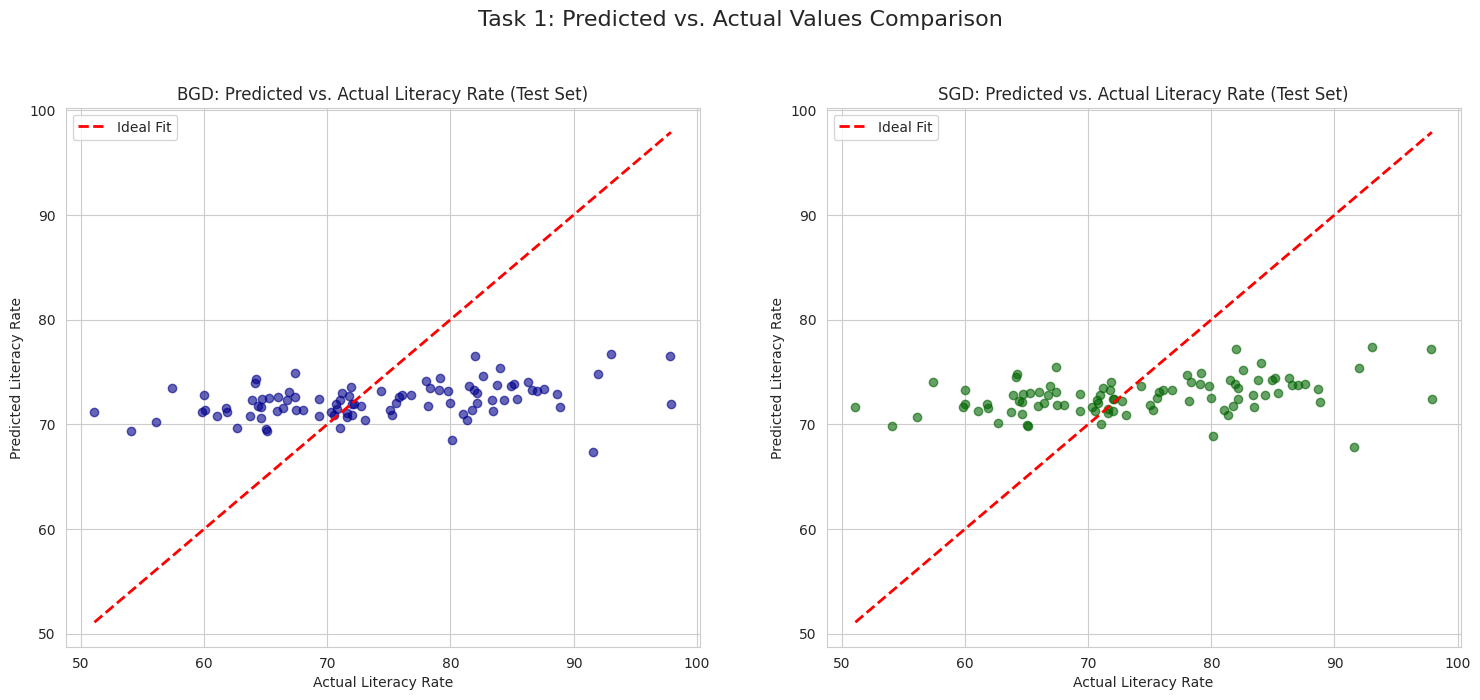

In [36]:
# --- 5. Predicted vs. Actual Scatter Plot and Residual Plot ---

# Predicted vs. Actual Plot
plt.figure(figsize=(18, 7))

plt.subplot(1, 2, 1)
plt.scatter(y_test, y_test_pred_bgd, color='darkblue', alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit')
plt.title('BGD: Predicted vs. Actual Literacy Rate (Test Set)')
plt.xlabel('Actual Literacy Rate')
plt.ylabel('Predicted Literacy Rate')
plt.legend()

plt.subplot(1, 2, 2)
plt.scatter(y_test, y_test_pred_sgd, color='darkgreen', alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit')
plt.title('SGD: Predicted vs. Actual Literacy Rate (Test Set)')
plt.xlabel('Actual Literacy Rate')
plt.ylabel('Predicted Literacy Rate')
plt.legend()
plt.suptitle('Task 1: Predicted vs. Actual Values Comparison', fontsize=16, y=1.02)
plt.show()

In [37]:
# Residual Plot
residuals_bgd = y_test - y_test_pred_bgd
residuals_sgd = y_test - y_test_pred_sgd


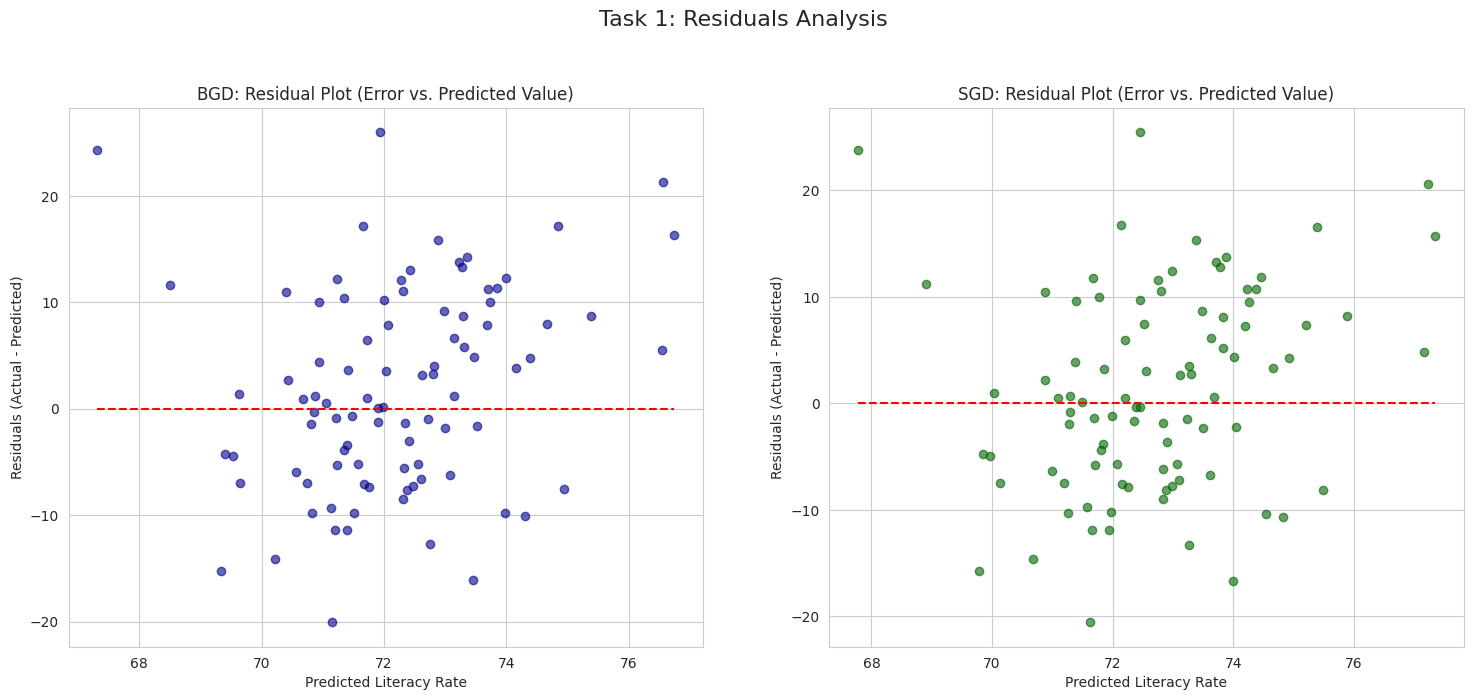

In [38]:

plt.figure(figsize=(18, 7))
plt.subplot(1, 2, 1)
plt.scatter(y_test_pred_bgd, residuals_bgd, color='darkblue', alpha=0.6)
plt.hlines(y=0, xmin=y_test_pred_bgd.min(), xmax=y_test_pred_bgd.max(), colors='red', linestyles='--')
plt.title('BGD: Residual Plot (Error vs. Predicted Value)')
plt.xlabel('Predicted Literacy Rate')
plt.ylabel('Residuals (Actual - Predicted)')

plt.subplot(1, 2, 2)
plt.scatter(y_test_pred_sgd, residuals_sgd, color='darkgreen', alpha=0.6)
plt.hlines(y=0, xmin=y_test_pred_sgd.min(), xmax=y_test_pred_sgd.max(), colors='red', linestyles='--')
plt.title('SGD: Residual Plot (Error vs. Predicted Value)')
plt.xlabel('Predicted Literacy Rate')
plt.ylabel('Residuals (Actual - Predicted)')
plt.suptitle('Task 1: Residuals Analysis', fontsize=16, y=1.02)
plt.show()

In [40]:
# ==============================================================================
# TASK 2: KNN CLASSIFIER (From Scratch)
# Target Variable: Categorized 'Literacy'
# ==============================================================================

print("\n" + "="*80)
print("TASK 2: K-NEAREST NEIGHBORS (KNN) CLASSIFIER")
print("="*80)

# --- 1. Prepare Data and Create Categorical Labels ---

# Create 'Literacy_Category' column based on the assignment rules
def categorize_literacy(rate):
    if rate < 65:
        return 'Low'
    elif 65 <= rate <= 85:
        return 'Medium'
    else: # rate > 85
        return 'High'

train_df['Literacy_Category'] = train_df['Literacy'].apply(categorize_literacy)
val_df['Literacy_Category'] = val_df['Literacy'].apply(categorize_literacy)
test_df['Literacy_Category'] = test_df['Literacy'].apply(categorize_literacy)

# Select features and labels for KNN
X_train_knn_raw = train_df[FEATURES].values
y_train_knn = train_df['Literacy_Category'].values
X_val_knn_raw = val_df[FEATURES].values
y_val_knn = val_df['Literacy_Category'].values
X_test_knn_raw = test_df[FEATURES].values
y_test_knn = test_df['Literacy_Category'].values

# MinMax Scaler for KNN (an alternative choice for distance-based algorithms)
class MinMaxScaler:
    def __init__(self):
        self.min = None
        self.max = None

    def fit(self, X):
        self.min = np.min(X, axis=0)
        self.max = np.max(X, axis=0)
        return self

    def transform(self, X):
        if self.min is None or self.max is None:
            raise Exception("Scaler not fitted. Call fit() first.")
        # Handle case where min == max
        range_ = self.max - self.min
        range_[range_ == 0] = 1.0
        return (X - self.min) / range_

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)


TASK 2: K-NEAREST NEIGHBORS (KNN) CLASSIFIER


In [41]:
# Scale features for KNN
scaler_knn = MinMaxScaler().fit(X_train_knn_raw)
X_train_knn = scaler_knn.transform(X_train_knn_raw)
X_val_knn = scaler_knn.transform(X_val_knn_raw)
X_test_knn = scaler_knn.transform(X_test_knn_raw)

# --- 2. Custom KNN Classifier Class ---
class KNearestNeighborsClassifier:
    def __init__(self, k=3):
        self.k = k

    def fit(self, X, y):
        # KNN is a lazy learning algorithm; it just stores the data
        self.X_train = X
        self.y_train = y
        return self

    def _euclidean_distance(self, x1, x2):
        """Calculates the Euclidean distance between two vectors."""
        return np.sqrt(np.sum((x1 - x2) ** 2))

    def _predict_single(self, x_test):
        """Predicts the class for a single test sample."""
        distances = []
        for x_train, y_train in zip(self.X_train, self.y_train):
            dist = self._euclidean_distance(x_test, x_train)
            distances.append((dist, y_train))

        # Sort by distance and get k nearest neighbors
        distances.sort(key=lambda x: x[0])
        k_nearest_neighbors = distances[:self.k]

        # Extract the labels of the k neighbors
        neighbor_labels = [label for dist, label in k_nearest_neighbors]

        # Determine the majority class (mode)
        most_common = Counter(neighbor_labels).most_common(1)
        return most_common[0][0]

    def predict(self, X_test):
        """Predicts the class for a batch of test samples."""
        predictions = [self._predict_single(x) for x in X_test]
        return np.array(predictions)


In [42]:
# --- 3. Custom Evaluation Metrics for Classification ---

def confusion_matrix(y_true, y_pred, labels):
    """Calculates the confusion matrix."""
    n_labels = len(labels)
    matrix = np.zeros((n_labels, n_labels), dtype=int)
    label_to_index = {label: i for i, label in enumerate(labels)}

    for true, pred in zip(y_true, y_pred):
        true_idx = label_to_index.get(true)
        pred_idx = label_to_index.get(pred)

        if true_idx is not None and pred_idx is not None:
             matrix[true_idx, pred_idx] += 1
    return matrix

def accuracy_score(y_true, y_pred):
    """Calculates the classification accuracy."""
    return np.mean(y_true == y_pred)

# --- 4. Training and Comparison (k=3, 5, 7) ---
K_VALUES = [3, 5, 7]
knn_models = {}
labels = np.unique(y_train_knn)

print("\nTraining and Evaluating KNN models (k=3, 5, 7) on Validation Set...")


Training and Evaluating KNN models (k=3, 5, 7) on Validation Set...


In [43]:
for k in K_VALUES:
    model = KNearestNeighborsClassifier(k=k)
    model.fit(X_train_knn, y_train_knn)
    y_val_pred = model.predict(X_val_knn)
    knn_models[k] = {
        'model': model,
        'predictions': y_val_pred,
        'accuracy': accuracy_score(y_val_knn, y_val_pred),
        'confusion_matrix': confusion_matrix(y_val_knn, y_val_pred, labels)
    }
    print(f"  -> k={k}: Validation Accuracy = {knn_models[k]['accuracy']:.4f}")

  -> k=3: Validation Accuracy = 0.6593
  -> k=5: Validation Accuracy = 0.6484
  -> k=7: Validation Accuracy = 0.7033


/tmp/ipython-input-1771538077.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=train_df['Literacy_Category'], order=labels, palette='viridis')


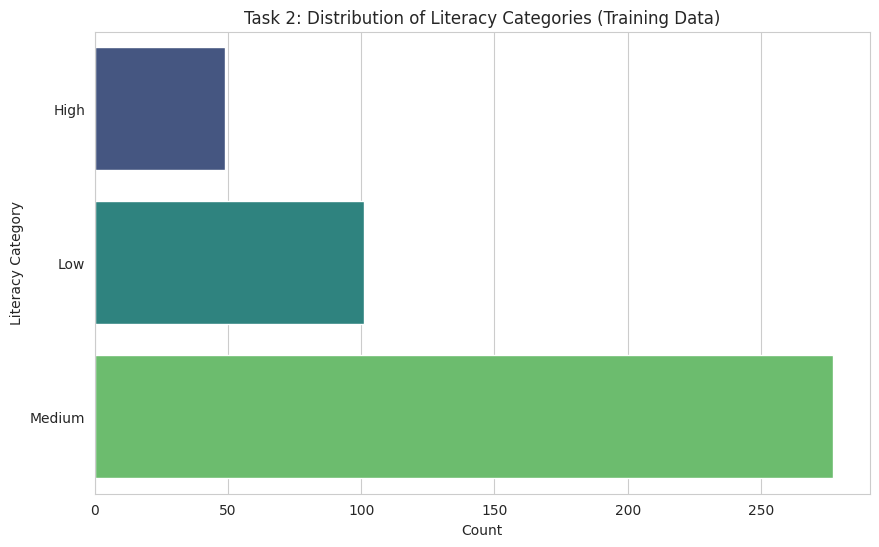

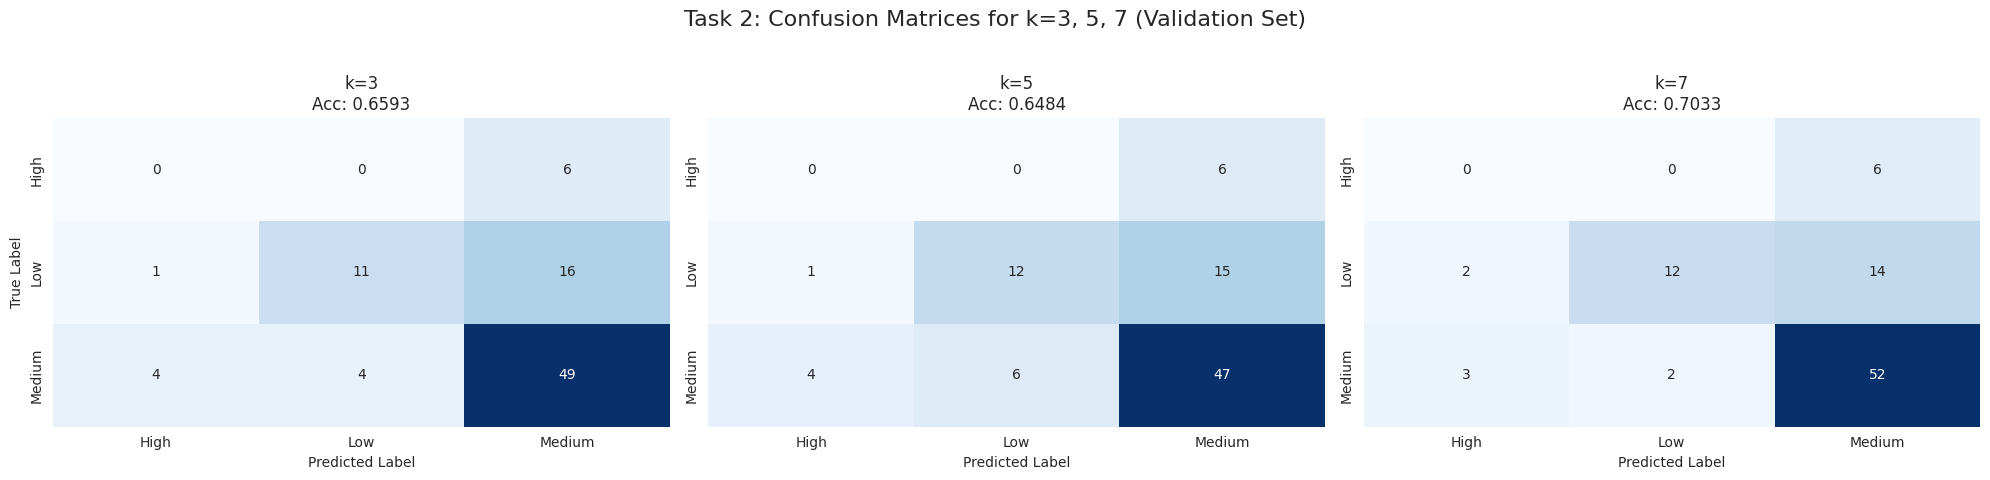

In [44]:
# --- 5. Visualizations for KNN ---

# a) Class Distribution Plot (Training Set)
plt.figure(figsize=(10, 6))
sns.countplot(y=train_df['Literacy_Category'], order=labels, palette='viridis')
plt.title('Task 2: Distribution of Literacy Categories (Training Data)')
plt.xlabel('Count')
plt.ylabel('Literacy Category')
plt.show()

# b) Confusion Matrices Plot
fig, axes = plt.subplots(1, len(K_VALUES), figsize=(20, 5))
fig.suptitle('Task 2: Confusion Matrices for k=3, 5, 7 (Validation Set)', fontsize=16)

for i, k in enumerate(K_VALUES):
    cm = knn_models[k]['confusion_matrix']
    ax = axes[i]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(f'k={k}\nAcc: {knn_models[k]["accuracy"]:.4f}')
    ax.set_xlabel('Predicted Label')
    if i == 0:
        ax.set_ylabel('True Label')
    else:
        ax.set_ylabel('') # Only label the first Y-axis

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [45]:
# --- 6. K-Fold Cross-Validation (on Training+Validation Sets) ---

# For CV, we combine training and validation data, keeping the test set fixed.
X_cv = np.concatenate((X_train_knn, X_val_knn), axis=0)
y_cv = np.concatenate((y_train_knn, y_val_knn), axis=0)
n_cv = len(X_cv)

def kfold_split(n_samples, n_splits=5):
    indices = np.random.permutation(n_samples)
    fold_sizes = np.full(n_splits, n_samples // n_splits, dtype=int)
    fold_sizes[:n_samples % n_splits] += 1
    current = 0
    folds = []
    for fold_size in fold_sizes:
        start, stop = current, current + fold_size
        folds.append(indices[start:stop])
        current = stop
    return folds

def cross_validate(X, y, k_list, n_splits=5):
    folds = kfold_split(len(X), n_splits)
    k_scores = {k: [] for k in k_list}

    print(f"\nRunning {n_splits}-Fold Cross-Validation on Training+Validation Data...")

    for i, test_fold_indices in enumerate(folds):
        # Create CV training and CV testing sets
        cv_train_indices = np.concatenate([folds[j] for j in range(n_splits) if j != i])

        X_cv_train, y_cv_train = X[cv_train_indices], y[cv_train_indices]
        X_cv_test, y_cv_test = X[test_fold_indices], y[test_fold_indices]

        print(f"  -> Fold {i+1}/{n_splits}")

        for k in k_list:
            model = KNearestNeighborsClassifier(k=k)
            model.fit(X_cv_train, y_cv_train)
            y_cv_pred = model.predict(X_cv_test)
            accuracy = accuracy_score(y_cv_test, y_cv_pred)
            k_scores[k].append(accuracy)

    # Calculate mean and standard deviation of scores
    mean_scores = {k: np.mean(scores) for k, scores in k_scores.items()}
    std_scores = {k: np.std(scores) for k, scores in k_scores.items()}

    return mean_scores, std_scores

# Run CV for k=3, 5, 7
mean_scores, std_scores = cross_validate(X_cv, y_cv, K_VALUES, n_splits=5)

print("\n--- Cross-Validation Results ---")
best_k = None
best_cv_score = -1
for k in K_VALUES:
    print(f"k={k}: Mean Accuracy = {mean_scores[k]:.4f} (Std Dev: {std_scores[k]:.4f})")
    if mean_scores[k] > best_cv_score:
        best_cv_score = mean_scores[k]
        best_k = k

print(f"\nBest k selected by CV: {best_k}")


Running 5-Fold Cross-Validation on Training+Validation Data...
  -> Fold 1/5
  -> Fold 2/5
  -> Fold 3/5
  -> Fold 4/5
  -> Fold 5/5

--- Cross-Validation Results ---
k=3: Mean Accuracy = 0.6776 (Std Dev: 0.0282)
k=5: Mean Accuracy = 0.6815 (Std Dev: 0.0218)
k=7: Mean Accuracy = 0.6872 (Std Dev: 0.0181)

Best k selected by CV: 7



--- Final Test Set Evaluation (Best k) ---
Best k: 7
Test Accuracy: 0.6413
Test Confusion Matrix:
['High' 'Low' 'Medium']
[[ 1  1 11]
 [ 0  5 14]
 [ 0  7 53]]


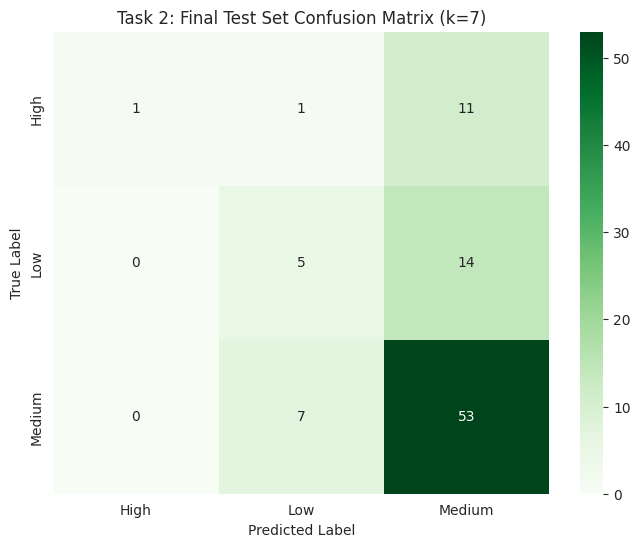

In [46]:

# --- 7. Final Evaluation on FIXED Test Set using the Best k ---

# Retrain the model using the entire Training+Validation set for the best k
final_knn_model = KNearestNeighborsClassifier(k=best_k)
final_knn_model.fit(X_cv, y_cv)

# Predict on the fixed Test Set
y_test_pred_knn = final_knn_model.predict(X_test_knn)
test_accuracy_knn = accuracy_score(y_test_knn, y_test_pred_knn)
test_cm_knn = confusion_matrix(y_test_knn, y_test_pred_knn, labels)

print("\n--- Final Test Set Evaluation (Best k) ---")
print(f"Best k: {best_k}")
print(f"Test Accuracy: {test_accuracy_knn:.4f}")
print("Test Confusion Matrix:")
print(labels)
print(test_cm_knn)

# Final Visualization: Test Set Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(test_cm_knn, annot=True, fmt='d', cmap='Greens',
            xticklabels=labels, yticklabels=labels)
plt.title(f'Task 2: Final Test Set Confusion Matrix (k={best_k})')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [48]:
def precision_score(y_true, y_pred, labels):
    """Calculates precision for each class and macro average."""
    cm = confusion_matrix(y_true, y_pred, labels)
    n_labels = len(labels)
    precision = {}
    for i, label in enumerate(labels):
        # True Positives for class i are at cm[i, i]
        # Predicted Positives for class i are the sum of the i-th column cm[:, i]
        true_positives = cm[i, i]
        predicted_positives = np.sum(cm[:, i])

        # Handle division by zero if no instances were predicted for this class
        precision[label] = true_positives / predicted_positives if predicted_positives > 0 else 0.0

    # Macro average precision
    macro_precision = np.mean(list(precision.values())) if precision else 0.0

    return precision, macro_precision

def accuracy_score_from_matrix(cm):
    """Calculates overall accuracy from a confusion matrix."""
    # Accuracy = (Sum of diagonal elements) / (Sum of all elements)
    correct_predictions = np.sum(np.diag(cm))
    total_predictions = np.sum(cm)
    return correct_predictions / total_predictions if total_predictions > 0 else 0.0

# Calculate precision and accuracy for the final KNN test set results
test_precision_knn, test_macro_precision_knn = precision_score(y_test_knn, y_test_pred_knn, labels)
test_accuracy_knn_from_matrix = accuracy_score_from_matrix(test_cm_knn)

print("\n--- Final Test Set Evaluation (Best k) - Additional Metrics ---")
print(f"Best k: {best_k}")
print(f"Test Accuracy (from matrix): {test_accuracy_knn_from_matrix:.4f}")
print("Test Precision per class:")
for label, precision in test_precision_knn.items():
    print(f"  {label}: {precision:.4f}")
print(f"Test Macro Average Precision: {test_macro_precision_knn:.4f}")



--- Final Test Set Evaluation (Best k) - Additional Metrics ---
Best k: 7
Test Accuracy (from matrix): 0.6413
Test Precision per class:
  High: 1.0000
  Low: 0.3846
  Medium: 0.6795
Test Macro Average Precision: 0.6880


In [49]:
def recall_score(y_true, y_pred, labels):
    """Calculates recall for each class and macro average."""
    cm = confusion_matrix(y_true, y_pred, labels)
    n_labels = len(labels)
    recall = {}
    for i, label in enumerate(labels):
        # True Positives for class i are at cm[i, i]
        # Actual Positives for class i are the sum of the i-th row cm[i, :]
        true_positives = cm[i, i]
        actual_positives = np.sum(cm[i, :])

        # Handle division by zero if no actual instances exist for this class
        recall[label] = true_positives / actual_positives if actual_positives > 0 else 0.0

    # Macro average recall
    macro_recall = np.mean(list(recall.values())) if recall else 0.0

    return recall, macro_recall

def f1_score(y_true, y_pred, labels):
    """Calculates F1-score for each class and macro average."""
    precision, _ = precision_score(y_true, y_pred, labels)
    recall, _ = recall_score(y_true, y_pred, labels)
    f1 = {}
    for label in labels:
        prec = precision.get(label, 0.0)
        rec = recall.get(label, 0.0)
        # Handle division by zero if both precision and recall are zero
        f1[label] = 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0.0

    # Macro average F1-score
    macro_f1 = np.mean(list(f1.values())) if f1 else 0.0

    return f1, macro_f1

In [50]:
# Calculate recall and f1 score for the final KNN test set results
test_recall_knn, test_macro_recall_knn = recall_score(y_test_knn, y_test_pred_knn, labels)
test_f1_knn, test_macro_f1_knn = f1_score(y_test_knn, y_test_pred_knn, labels)

print(f"Best k: {best_k}")

print("\nTest Recall per class:")
for label, recall in test_recall_knn.items():
    print(f"  {label}: {recall:.4f}")
print(f"Test Macro Average Recall: {test_macro_recall_knn:.4f}")


print("\nTest F1 Score per class:")
for label, f1 in test_f1_knn.items():
    print(f"  {label}: {f1:.4f}")
print(f"Test Macro Average F1 Score: {test_macro_f1_knn:.4f}")

print("\nScript execution complete. The visualizations are displayed inline.")

Best k: 7

Test Recall per class:
  High: 0.0769
  Low: 0.2632
  Medium: 0.8833
Test Macro Average Recall: 0.4078

Test F1 Score per class:
  High: 0.1429
  Low: 0.3125
  Medium: 0.7681
Test Macro Average F1 Score: 0.4078

Script execution complete. The visualizations are displayed inline.
